# Interfacing Keldysh model with TTM

Documentation of the library is given here: 
http://cybertib.celeonet.fr/spp-extended-theory/namespacelibKeldysh.html

and details as
gammaKeldysh (Egap, meff, Efield, wavelength, RefractiveIndex=1.)

In [1]:
from spp_extended_theory.Keldysh.libKeldysh import gammaKeldysh, Keldysh1phi, Keldysh2theta, EffectiveGap, KeldyshFunction_Gruzdev, IonizationRate_Gruzdev
# from spp_extended_theory.Keldysh    import Keldysh
from scipy.constants import e, h, hbar, c, epsilon_0
import numpy as np

In [2]:
Egap=9*e
wavelength=2.08e-6 #m
NumberOfPhotons=np.ceil((h*c/wavelength)**-1 * Egap)
print("Number of MPI photons: ", NumberOfPhotons)
meff=1e0
Efield=np.linspace(1,1E10,10)
intensity=0.5*c*epsilon_0*Efield**2
print(intensity)
print(np.shape(Efield))
gammaKeldysh(Egap, meff, Efield, wavelength)

Number of MPI photons:  16.0
[1.32720936e-03 1.63853008e+15 6.55412032e+15 1.47467707e+16
 2.62164813e+16 4.09632520e+16 5.89870829e+16 8.02879739e+16
 1.04865925e+17 1.32720936e+17]
(10,)


array([6.47810215e+09, 5.83029193e+00, 2.91514597e+00, 1.94343064e+00,
       1.45757298e+00, 1.16605839e+00, 9.71715323e-01, 8.32898848e-01,
       7.28786492e-01, 6.47810215e-01])

# Ideas 

A great page that makes a nice summary of the possibilities https://scipy-lectures.org/advanced/interfacing_with_c/interfacing_with_c.html

## 1. Simplest interface
1. Generate the file containing wPI[internal intensities]
1. Write it into a file
1. Load the file in memory with Flirt C code. 
1. Interpolate linearly between the intensities to compute the right value for execution (RAM based only). 

## 2. A bit more integration
1. To prepare the contents in memory using libKeldysh. 
1. To transfer the memory content directly to C (using Numpy C API: https://numpy.org/doc/stable/reference/c-api/coremath.html#numpy-core-math-library). Think that elliptical functions are necessary for Keldysh routines. 

## 3. Wrapping Flirt code into Cython.
1. ?

# Implementation

## Simplest interface

This first part is doing something equivalent to keldysh.py, better summarized. 

In [3]:
from octopus_slabs.Libs.libMaterials import SiBulkReal300K
import numpy as np
import matplotlib.pyplot as plt
from scipy.constants import c, epsilon_0

Egap, meff, OpticalIndex = SiBulkReal300K()
print(Egap/e)

3.0999999999999996


## Should we get wavelength in input file? 

In [4]:
wavelength = 800E-9

# Here we shall define min and max of intensity necessary for 1 run.

LogPeakIntensity=np.arange(0,18,1E-3)
PeakIntensity = np.power(10.,LogPeakIntensity) #Zhukov example at 1.6 um
RefractiveIndex = OpticalIndex[wavelength] #1: for far field, # 1.45: for near field in silica
PeakField   = np.sqrt(2e0 * PeakIntensity * RefractiveIndex / (c * epsilon_0))
order=200

In [5]:
gamma   = gammaKeldysh(Egap, meff, PeakField, wavelength)
k1      = Keldysh1phi(gamma); k2 = Keldysh2theta(gamma)
EgapEff = EffectiveGap(Egap, k1, k2)
KeldyshFunctionResultG = KeldyshFunction_Gruzdev( k1, k2, EgapEff, order, wavelength )
wPIg    = IonizationRate_Gruzdev(k1, k2, KeldyshFunctionResultG, EgapEff, wavelength, meff)

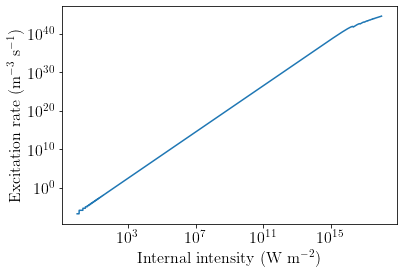

In [6]:
plt.loglog(PeakIntensity, wPIg, "-")
plt.xlabel(r"Internal intensity (W m$^{-2}$)")
plt.ylabel(r"Excitation rate (m$^{-3}$ s$^{-1}$)")
plt.show()

We are now able to grab a Keldysh excitation rate $w_{PI}$ directly from a set of parameters. 

In [7]:
import spp_extended_theory.Libs.libDatabase as libDatabase
ArrayToExport=np.array([PeakIntensity, np.log10(wPIg)]).T
libDatabase.ExportToTxt(ArrayToExport, "Keldysh.dat", header="Gap: "+str(round(Egap/e,1))+"eV\nWavelength: "+str(1E9*wavelength)+"nm"+"\nn x I\tWpiKG")

0

The second part is now preparing a database of Keldysh excitation rates for a number of fields. This is equivalent to the function libKeldysh.generateWpiTables(). 

In [8]:
!pwd

/home/hilase/Documents/octopus-slabs/Maths
